# Constructing and simulating simple models of somatic evolution

## Introduction

This notebook introduces evolutionary modelling approaches for simulating clonal competition in the healthy aging tissue. We examine neutral and non-neutral competition using Wright-Fisher and Moran process models, and consider the impact of the tissue structure on evolutionary processes. 

Here you simulate *clonal dynamics* in tissues. This is directly relevant to *lineage tracing* experiments but also genomic and other omic datasets that allow you to measure or infer clonal dynamics such as sequencing or methylation clocks. It is recommended that you read the following papers for insights into these experiments.

- Colom B, Alcolea MP, Piedrafita G, Hall MWJ, Wabik A, Dentro SC, Fowler JC, Herms A, King C, Ong SH, Sood RK, Gerstung M, Martincorena I, Hall BA, Jones PH. Spatial competition shapes the dynamic mutational landscape of normal esophageal epithelium. Nat Genet. 2020 Jun;52(6):604-614. doi: 10.1038/s41588-020-0624-3. Epub 2020 May 18. PMID: 32424351; PMCID: PMC7116672.
- Fowler JC, King C, Bryant C, Hall MWJ, Sood R, Ong SH, Earp E, Fernandez-Antoran D, Koeppel J, Dentro SC, Shorthouse D, Durrani A, Fife K, Rytina E, Milne D, Roshan A, Mahububani K, Saeb-Parsy K, Hall BA, Gerstung M, Jones PH. Selection of Oncogenic Mutant Clones in Normal Human Skin Varies with Body Site. Cancer Discov. 2021 Feb;11(2):340-361. doi: 10.1158/2159-8290.CD-20-1092. Epub 2020 Oct 21. PMID: 33087317; PMCID: PMC7116717.
- Abby E, Dentro SC, Hall MWJ, Fowler JC, Ong SH, Sood R, Herms A, Piedrafita G, Abnizova I, Siebel CW, Gerstung M, Hall BA, Jones PH. Notch1 mutations drive clonal expansion in normal esophageal epithelium but impair tumor growth. Nat Genet. 2023 Feb;55(2):232-245. doi: 10.1038/s41588-022-01280-z. Epub 2023 Jan 19. PMID: 36658434; PMCID: PMC9925379.

In this notebook you will learn
- the basics of how to run, analyse, and visualise different systems
- how the choice of different approaches depends on the questions you are asking
    - Moran vs Wright Fisher computational performance
    - How drift influences clonal survival and takeover
    - How space influences clonal survival and takeover
    - How the nature of competition in the tissue impacts all of these features

Parameters are set globally and retained for all simulations to enable direct comparison between simulation types.

This notebook has less coding than following notebooks that apply the knowledge here. However you will need to apply the learning here in other notebooks so it is important you engage with the content and not simply run the code and move on.

## Simulating clonal dynamics

The library used for performing simulations here is

https://github.com/michaelhall28/clone-competition-simulation

You are not expected to work directly with the code in this practical, but we reference specific parts of the code for those interested.

### Algorithms of Wright-Fisher and Moran processes

This is a brief reminder of the algorithms being applied here, as discussed in the lectures. 

In the Wright-Fisher model (*wf.py*) an update replaces all cells in the tissue. An entire population of new cells are randomly created based on weights reflecting clone sizes and fitnesses of the previous population. An update represents a generational replacement and can be related to time through the division rate. Biologically it could be compared to divisions in a tissue that occur concurrently through a circadian control.

In the Moran process model (*moran.py*) an update selects one cell to die, and then selects one cell to replace it based on weights reflecting clone sizes and fitnesses of the previous population. This update reflects a single division and provides a continuous series of division events. 

These models have distinct properties that present themselves in different circumstances. Wright-Fisher models simulate dynamics faster, but have slower genetic *drift* due to reduced variance. This can effectively slow down some clonal dynamics in the model, which we will explore below. The choice of model therefore can be a tradeoff between accuracy and performance.

### Space constrains growth

Stem cells in squamous epithelial tissues do not mix freely. Cells form regular hexagonal arrays, and so when dividing cannot replace any cell from the previous population but rather only their six neighbours. The code allows you to consider the pool of replacing neighbours as a neighbourhood of 6 (adajcent cells) or 7 (adjacent cells plus the cell being replaced). Following the update algorithms above, Moran (*moran2D.py*) more naturally lends itself to the 6 cell neighbourhood whilst Wright-Fisher (*wf2D.py*) to the 7 cell neighbourhood.

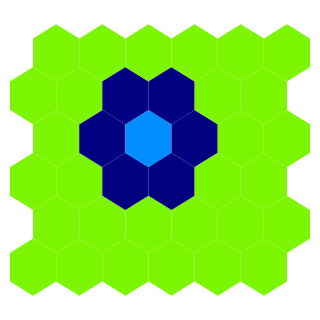

*Cell neighbourhoods in a hexagonal grid. The cell being replaced is light blue, and the 6 cell neighbourhood used typically in Moran processes in dark blue. The 7 cell neighbourhood used in Wright-Fisher models is all blue cells* 

## Exploring neutral dynamics and homeostasis

We will first build simulations of populations of cells neutrally competing. 

Before running simulations, we will import the modules that we are using throughout the code and specifying global parameters that all simulations are going to share. Out of convention and to ease reading we have named these global variables with all-capital letters.

In [1]:
from clone_competition_simulation import Parameters, PopulationParameters, TimeParameters, FitnessParameters, LabelParameters
import matplotlib.pyplot as plt
import numpy as np

In [2]:
MAX_TIME=25 # Run for 25 time units (e.g. weeks)
DIVISION_RATE=1.4 # Set average division rate for all cells to 1.4 per time unit
SELECTIVE_FITNESS = 1.3
NEUTRAL_FITNESS = 1

Our first model is a neutral system built as a Wright-Fisher process. We specify that there are 10000 cells in total, split into two clonal populations representing 90 and 10 % of the total system. To specify that the competition of the two populations should be neutral we state that their individual fitnesses are both set to the neutral global parameter (*NEUTRAL_FITNESS*).

In this simulator, we create a *Parameters* object with a series of arguments reflecting simulation settings. Here we specify the *algorithm* we are using, and objects representing the *times*, *population*, and *fitness* parameters. We pass complex sets of arguments as objects as this allows us to verify the selections on creation. As combinations of parameters are potentially complex this is a useful error checking approach.

*Question - how would you expect the model to change if both populations had their fitnesses set to *SELECTIVE_FITNESS**

To demonstrate model efficiency, we have recorded the time taken to perform a simulation using the jupyter command %%time. Record the total CPU time. As we are running a short simulation the simulations built-in time monitor may appear to hang (as the simulation completes before the ticker is updated)- this is normal and to be expected.

In [3]:
pWF = Parameters(
    algorithm='WF',  # We will run a non-spatial Wright-Fisher simulation. 
    times=TimeParameters(
        max_time=MAX_TIME,  # Run for 25 time units
        division_rate=DIVISION_RATE
    ), 
    population=PopulationParameters(  # Define the cell population
        initial_size_array=[9000, 1000]  # There are three initial clones, with 100 cells in each
    ),
    fitness=FitnessParameters(  # Define the cell fitness
        initial_fitness_array=[NEUTRAL_FITNESS, NEUTRAL_FITNESS]    # Each clone has the same fitness value
    )
)

In [4]:
%%time

simWF = pWF.get_simulator()
simWF.run_sim()

Output()

CPU times: user 65.1 ms, sys: 28.5 ms, total: 93.6 ms
Wall time: 357 ms


The simulation has completed and we can now examine how the populations change over time. As we are examining neutral evolution, and the population size is fixed (through the model) we expect that the relative population sizes remain constant over time as they reflect a homeostasis. We can visualise this as a Müller plot, where clonal dynamics is visualised as a tightly packed stacked bar chart, with different population mixes rendered against time.

*Question- describe what homeostasis looks like in this model. Are the relative populations absolutely fixed across time?*

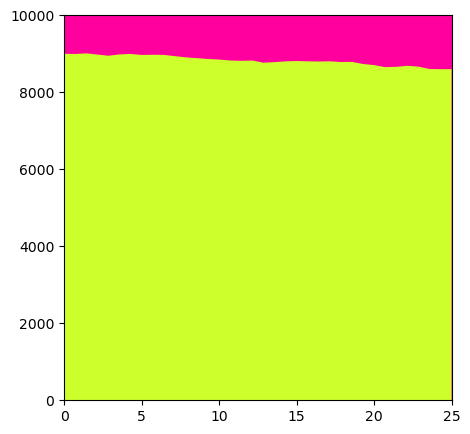

In [5]:
simWF.muller_plot(figsize=(5, 5))
plt.show()

We next test the dynamics of a Moran process sharing the same parameters as the earlier Wright-Fisher process. We set up the model in the same way, changing only the algorithm argument to 'Moran'. We run the new simulation, calculate the time, and generate a Müller plot.

In [6]:
pM = Parameters(
    algorithm='Moran',  # We will run a non-spatial Moran simulation. 
    times=TimeParameters(
        max_time=MAX_TIME,  
        division_rate=DIVISION_RATE  
    ), 
    population=PopulationParameters(  # Define the cell population
        initial_size_array=[9000, 1000]  # There are three initial clones, with 100 cells in each
    ),
    fitness=FitnessParameters(  # Define the cell fitness
        initial_fitness_array=[NEUTRAL_FITNESS, NEUTRAL_FITNESS]    # Each clone has the same fitness value
    )
)

In [7]:
%%time

simM = pM.get_simulator()
simM.run_sim()

Output()

CPU times: user 6.65 s, sys: 620 ms, total: 7.27 s
Wall time: 25.9 s


In [1]:
# Make a muller plot!

# YOUR CODE HERE 
raise NotImplementedError

NotImplementedError: 

*Question- which simulation was faster? Why is this?*

*Question - how does the homoestatic state differ between the Moran process from the Wright-Fisher process?*

*Task - repeat the above simulations with 10, 100, & 1000 fold fewer cells, and with the smaller population taking 5%, 1%, 0.1% and 0.01% of the total population.*

*Question - How does this change the maintenance of homeostasis? Is this consistent in both Moran and Wright-Fisher processes? Why do they differ?*

## Exploring clonal dynamics

These simulations give a clear view of the global dynamics of large populations, but typically we wish to track *clones*- the set of cells descended from a single cell labelled at some point in time. The dynamics of single cells and small clones is quite different from large populations- to help illustrate this we can plot the mean clone size of the previous Moran process over time.

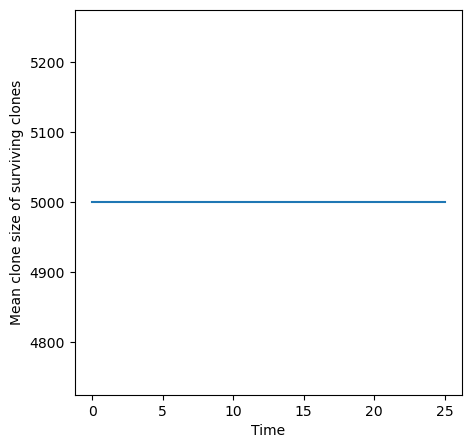

In [9]:
fig, ax=plt.subplots(figsize=(5, 5))
simM.plot_mean_clone_size_graph_for_non_mutation(show_spm_fit=False, legend_label='Moran', 
                                              fit_plot_kwargs={'c': 'r', 'linestyle': '--'}, ax=ax
                                                )

We can then run an alternative Moran simulation where every cell is a unique clone, and repeat the analysis. When plotting the mean clone size here we can compare it with the expected dynamics of the single progenitor model- a commonly used model that recapitulates the long term dynamics of most epithelial tissues.



In [10]:
# Run a simulation with 10000 single cell clones.  
pMc = Parameters(
    algorithm='Moran', 
    times=TimeParameters(max_time=MAX_TIME, division_rate=DIVISION_RATE), 
    population=PopulationParameters(initial_size_array=np.ones(10000))
)
sMc = pMc.get_simulator()
sMc.run_sim()

Output()

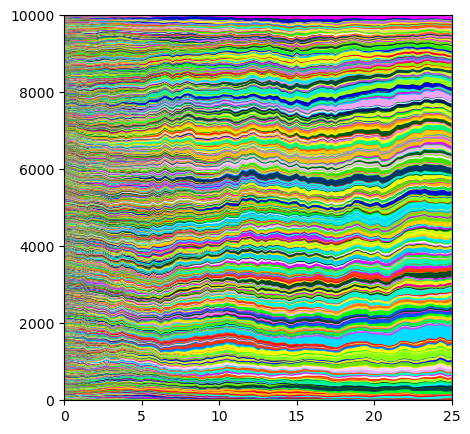

In [11]:

sMc.muller_plot(figsize=(5, 5))
plt.show()

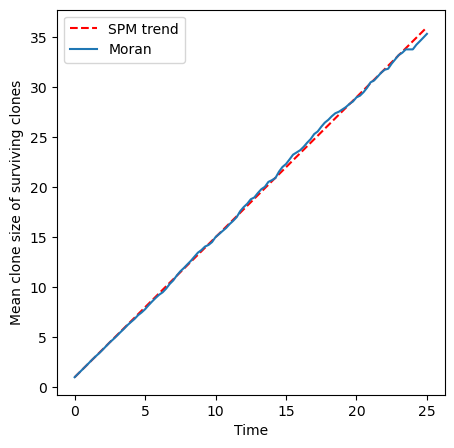

In [12]:
fig, ax=plt.subplots(figsize=(5, 5))
sMc.plot_mean_clone_size_graph_for_non_mutation(show_spm_fit=True, legend_label='Moran', legend_label_fit='SPM trend',
                                              fit_plot_kwargs={'c': 'r', 'linestyle': '--'}, ax=ax
                                                )
plt.legend()
plt.show()

*Question - why does mean clone size grow when the system is competing neutrally?*



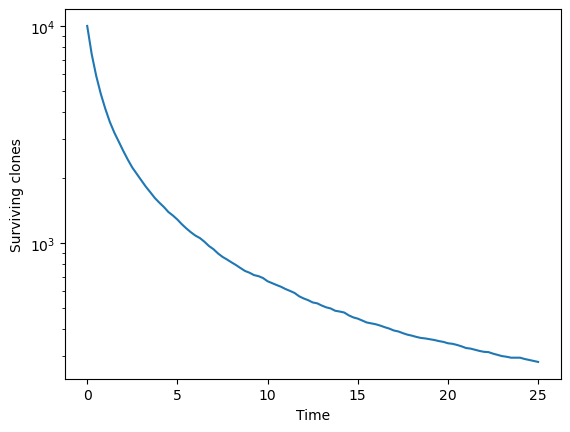

In [13]:
sMc.plot_surviving_clones_for_non_mutation()


If we switch our models to Wright-Fisher, we can see a clear change that results from the choice of model. The variance in allele frequency (*drift* in genetics terms) in Wright-Fisher models is half of that of the Moran process due to the whole-population update. This leads to a reduction in mean clone size growth that is not as apparent when looking at large clonal populations. For neutral systems this has implications for clone survival too. Typically when simulating these properties with a Wright-Fisher model you may therefore double the division rate.

In [14]:
# Run a simulation with 10000 single cell clones.  
pWFc = Parameters(
    algorithm='WF', 
    times=TimeParameters(max_time=MAX_TIME, division_rate=DIVISION_RATE), 
    population=PopulationParameters(initial_size_array=np.ones(10000))
)
sWFc = pWFc.get_simulator()
sWFc.run_sim()

Output()

In [2]:
# Use the function plot_mean_clone_size_graph_for_non_mutation as above on the Wright-Fisher simulation

# YOUR CODE HERE 
raise NotImplementedError


NotImplementedError: 

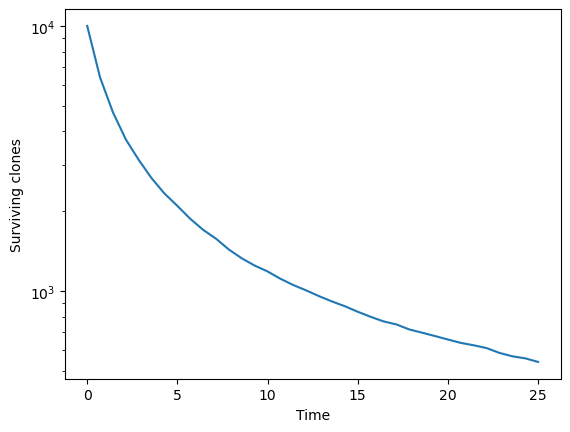

In [16]:
sWFc.plot_surviving_clones_for_non_mutation()


## Spatial models

Spatial constraints on competition also alter clonal growth. Once a cell is restricted in space to competing with immediately adjacent neighbours the growth of large clones is effectively constrained to the leading edge of the clone, resulting in growth slowing over time. This can be most clearly seen by the Moran process models deviation from the single progenitor model.

Spatial models are implemented as a 2D hexagonal grid in this software library, where each cell has six neighbours. We can use implementations of either the Moran process or Wright-Fisher as we can for non-spatial models. For this class of models we can perform all of the analysis we have used for non-spatial models (survival, mean clone size, Müller plots etc), and extend it to include a visualisation of the tissue directly (i.e. the hexagonal 2D grid).

In [3]:
# Run a 2D Moran simulation with 10000 single cell clones.  
# The Parameters object should use the 'Moran2D' algorithm
# The PopulationParameters needs a initial_grid=np.arange(10000).reshape(100,100) 
# instead of initial_size_array=np.ones(10000), to indicate the shape of the tissue

# YOUR CODE HERE 
raise NotImplementedError


NotImplementedError: 

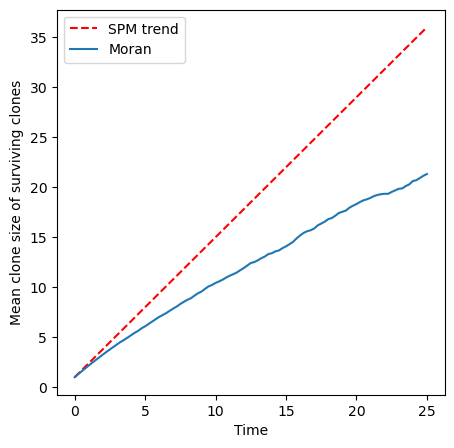

In [18]:
fig, ax=plt.subplots(figsize=(5, 5))
sM2D.plot_mean_clone_size_graph_for_non_mutation(show_spm_fit=True, legend_label='Moran', legend_label_fit='SPM trend',
                                              fit_plot_kwargs={'c': 'r', 'linestyle': '--'}, ax=ax
                                                )
plt.legend()
plt.show()

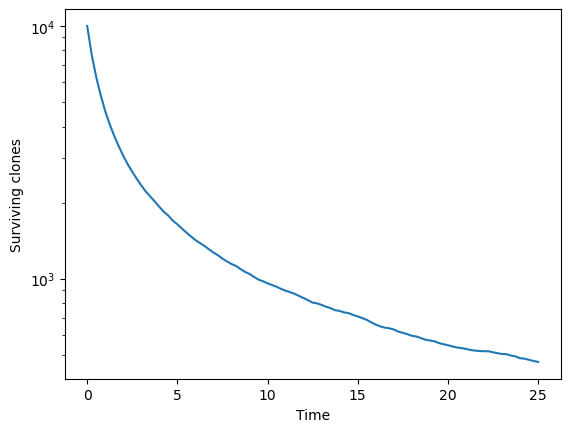

In [19]:
sM2D.plot_surviving_clones_for_non_mutation()


Clones in spatial simulations can additionally be plotted to draw out their relative positions in space. A single image gives a map of clonal takeover as below;

(np.float64(-0.5), np.float64(100.0000001), np.float64(-0.5), np.float64(50.0))

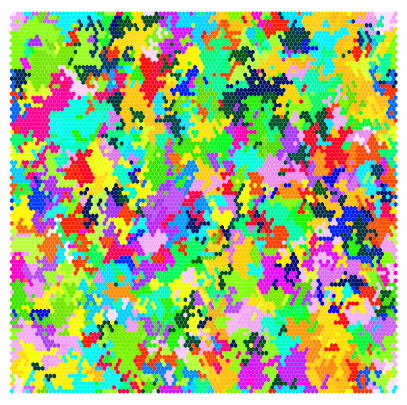

In [20]:
fig, ax = plt.subplots(figsize=(5, 5))
sM2D.plot_grid(ax=ax)
ax.set_aspect('auto')  
plt.axis('off')

Whilst the spread of clones can be rendered into a video. The below code generates a video showing how clones die and spread

In [21]:
from clone_competition_simulation.plotting.animator import HexAnimator

animator = HexAnimator(sM2D, figsize=(5, 5), equal_aspect=False)

original_setup = animator._setup_polygons_and_frame.__func__

def patched_setup(self):
    original_setup(self)
    self.ax.set_aspect(self.aspect)  # override the hardcoded 'equal'

import types
animator._setup_polygons_and_frame = types.MethodType(patched_setup, animator)

animator.animate("sM2D.mp4")

Finally, a 2D variant of the Wright-Fisher model is also implemented

In [22]:
# Run a simulation with 100000 single cell clones.  
pWF2D = Parameters(
    algorithm='WF2D', 
    times=TimeParameters(max_time=25, division_rate=1.4),
    population=PopulationParameters(initial_grid=np.arange(10000).reshape(100,100),cell_in_own_neighbourhood=True)
)
sWF2D = pWF2D.get_simulator()
sWF2D.run_sim()

Output()

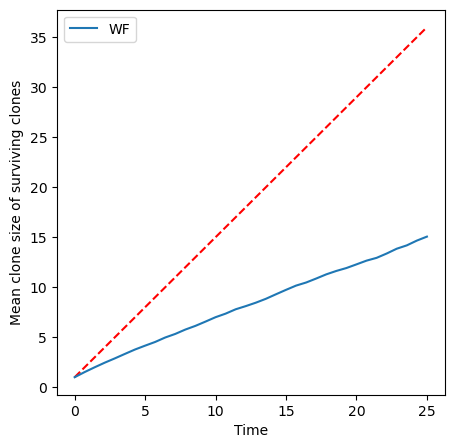

In [23]:
fig, ax=plt.subplots(figsize=(5, 5))
sWF2D.plot_mean_clone_size_graph_for_non_mutation(show_spm_fit=True, legend_label='WF', 
                                              fit_plot_kwargs={'c': 'r', 'linestyle': '--'}, ax=ax
                                                )
plt.legend()
plt.show()

(np.float64(-0.5), np.float64(100.0000001), np.float64(-0.5), np.float64(50.0))

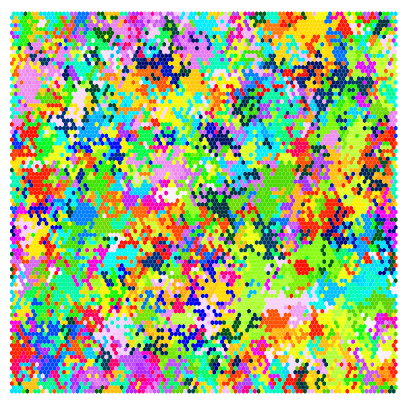

In [24]:
fig, ax = plt.subplots(figsize=(5, 5))
sWF2D.plot_grid(ax=ax)
ax.set_aspect('auto')  
plt.axis('off')

## Non neutral simulations

Neutral models inform us about the mutational dynamics of the unmutated tissues. As we age we accrue mutations that increase clonal fitness and enable clonal persistance, colonisation, and eventually takeover. Analysis of the ratio of non-synonymous to synonymous mutations in aged healthy tissues indicates that they are dominated by non-neutral clones, and dominant mutations found in the tissue have been shown in model systems to increase fitness.

To illustrate the growth, we will simulate a Wright Fisher model with two populations; 50 cells with a higher fitness and 9950 with a lower fitness. To assist the visualisation, we treat all 9950 "neutral" cells as one large clone, and all 50 "fit" cells as individual clones. We further add a label in the code so we can select out the fit cells.

We can run the simulation, and then compare the non-neutral clone sizes with the neutral clones simulated earlier. We can further plot the survival and generate a Muller plot, noting the key differences.

*Task- note that the survival comparison is not particularly useful as they are plotted as absolute survival rather than fractional. Referencing the original code, src/clone_competition_simulation/simulation_algorithms/simulation_plotting.py line 773, replot the figure with relative values*

*Question- growth of non-neutral clones starts exponentially but can be seen to slow down. What is happening?*

In [25]:
# Run a simulation with 9950 wild type cells and 50 single-cell clones with higher fitness. 
p = Parameters(
    algorithm='WF',
    times=TimeParameters(max_time=MAX_TIME, division_rate=DIVISION_RATE), 
    population=PopulationParameters(
        initial_size_array=np.concatenate([
            np.array([9950]),   # The wild type cells tracked as one big clone
            np.ones(50)]   # 50 single-cell clones
    )),
    fitness=FitnessParameters(
        initial_fitness_array=np.concatenate([
            [1],   # Wild type cells with fitness 1
            np.full(50, SELECTIVE_FITNESS)  # The next 50 clones given fitness 1.3
            ])
    ),
    labels=LabelParameters(
        initial_label_array=np.concatenate([
            [0],  # Wild type clone labelled with 0
            np.ones(50)  # Mutant clones labelled with 1
            ])
    )
)
wf_nn = p.get_simulator()
wf_nn.run_sim()

Output()

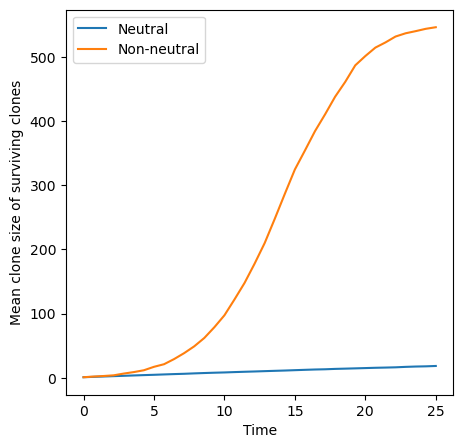

In [26]:
# The clones with fitness>1 grow faster than the neutral clones. 
fig, ax=plt.subplots(figsize=(5, 5))
sWFc.plot_mean_clone_size_graph_for_non_mutation(ax=ax, legend_label='Neutral', show_spm_fit=False)

# Use the label option to plot only the clones labelled with 1. 
wf_nn.plot_mean_clone_size_graph_for_non_mutation(label=1, legend_label='Non-neutral', ax=ax, show_spm_fit=False)

plt.legend()
plt.show()

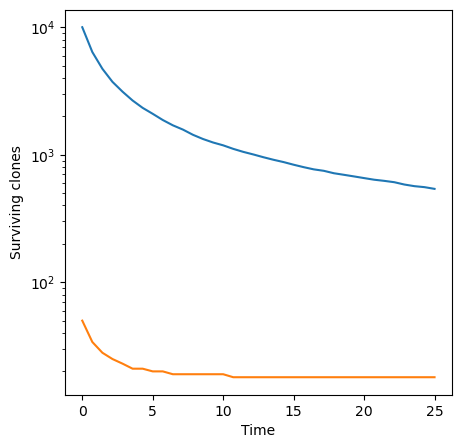

In [27]:
fig, ax=plt.subplots(figsize=(5, 5))
sWFc.plot_surviving_clones_for_non_mutation(ax=ax)
wf_nn.plot_surviving_clones_for_non_mutation(ax=ax,label=1)


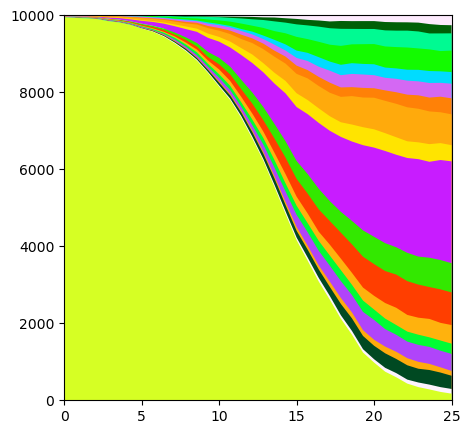

In [28]:
wf_nn.muller_plot(figsize=(5, 5))
plt.show()

## Final tasks

Finally all simulations can be performed with Moran processes, and in spatial variations. Perform a comparison of the models with one another with one another and their neutral counterparts.

Wright-Fisher and Moran neutral models differ strongly in clonal survival and clone growth. Does this difference hold for non-neutral growth? Is the effect of space on clonal growth more or less pronounced?

In [29]:
# YOUR CODE HERE 
raise NotImplementedError

Output()